# Self-Driving Car — Corrected Training Notebook

This notebook trains a steering-angle regression model from the Udacity-style `driving_log.csv` dataset.

## Before running
1. Keep this notebook in the project folder.
2. Confirm the dataset is available at `track/driving_log.csv` and images are in `track/IMG/`.
3. Use a Python environment with compatible TensorFlow, NumPy, OpenCV, pandas, scikit-learn, and Matplotlib versions.
4. Run cells from top to bottom. Do **not** put `pip install` commands inside the notebook; install dependencies in the terminal so the environment is reproducible.

This notebook fixes the recorded missing imports, duplicate data-loader function, train/validation leakage risk, malformed training argument, and Colab-only model download step. The exact TensorFlow/NumPy versions still need to be matched to the Python version installed on your PC.


In [5]:

import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("CUDA build:", tf.test.is_built_with_cuda())
print("GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.10.1
CUDA build: True
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:

import subprocess

result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout if result.returncode == 0 else result.stderr)


Return code: 0
Sat Oct 17 22:12:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.62                 KMD Version: 610.62        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   46C    P8              1W /   70W |    4389MiB /   6141MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------------------------

In [7]:
from pathlib import Path
import random
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python/TensorFlow:", tf.__version__)
print("Visible GPUs:", tf.config.list_physical_devices("GPU"))


Python/TensorFlow: 2.10.1
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "track"
CSV_PATH = DATA_DIR / "driving_log.csv"
IMAGE_DIR = DATA_DIR / "IMG"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 64
EPOCHS = 10
VALIDATION_SPLIT = 0.2
LEFT_RIGHT_CORRECTION = 0.15

if not CSV_PATH.is_file():
    raise FileNotFoundError(
        f"Cannot find {CSV_PATH}. Put this notebook in the project folder "
        "or change DATA_DIR to the folder containing driving_log.csv."
    )
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"Cannot find image folder {IMAGE_DIR}. Check the dataset folder structure."
    )

print("Dataset CSV:", CSV_PATH.resolve())
print("Image folder:", IMAGE_DIR.resolve())


Dataset CSV: C:\Users\sarva\Desktop\All projects\Self_Driving_Car\track\driving_log.csv
Image folder: C:\Users\sarva\Desktop\All projects\Self_Driving_Car\track\IMG


In [9]:

columns = ["center", "left", "right", "steering", "throttle", "reverse", "speed"]
data = pd.read_csv(CSV_PATH, header=None, names=columns)
data["steering"] = pd.to_numeric(data["steering"], errors="coerce")
data = data.dropna(subset=["center", "left", "right", "steering"]).copy()

for col in ["center", "left", "right"]:
    data[col] = data[col].astype(str).map(lambda p: IMAGE_DIR / Path(p.strip().replace("\\", "/")).name)

missing = sorted({str(p) for col in ["center", "left", "right"] for p in data[col] if not p.is_file()})
if missing:
    print(f"Warning: {len(missing)} referenced images are missing. Examples:")
    for item in missing[:10]:
        print(" -", item)
    valid_rows = data[["center", "left", "right"]].apply(lambda row: all(p.is_file() for p in row), axis=1)
    data = data.loc[valid_rows].reset_index(drop=True)

if len(data) < 10:
    raise ValueError(f"Only {len(data)} valid driving rows found. Check CSV/image paths.")

print("Valid driving rows:", len(data))
display(data.head())


Valid driving rows: 4053


,center,left,right,steering,throttle,reverse,speed
0,c:\Users\sarva\Desktop\All projects\Self_Drivi...,c:\Users\sarva\Desktop\All projects\Self_Drivi...,c:\Users\sarva\Desktop\All projects\Self_Drivi...,0.0,0.0,0.0,0.649786
1,c:\Users\sarva\Desktop\All projects\Self_Drivi...,c:\Users\sarva\Desktop\All projects\Self_Drivi...,c:\Users\sarva\Desktop\All projects\Self_Drivi...,0.0,0.0,0.0,0.627942
2,c:\Users\sarva\Desktop\All projects\Self_Drivi...,c:\Users\sarva\Desktop\All projects\Self_Drivi...,c:\Users\sarva\Desktop\All projects\Self_Drivi...,0.0,0.0,0.0,0.622910
3,c:\Users\sarva\Desktop\All projects\Self_Drivi...,c:\Users\sarva\Desktop\All projects\Self_Drivi...,c:\Users\sarva\Desktop\All projects\Self_Drivi...,0.0,0.0,0.0,0.619162
4,c:\Users\sarva\Desktop\All projects\Self_Drivi...,c:\Users\sarva\Desktop\All projects\Self_Drivi...,c:\Users\sarva\Desktop\All projects\Self_Drivi...,0.0,0.0,0.0,0.615438


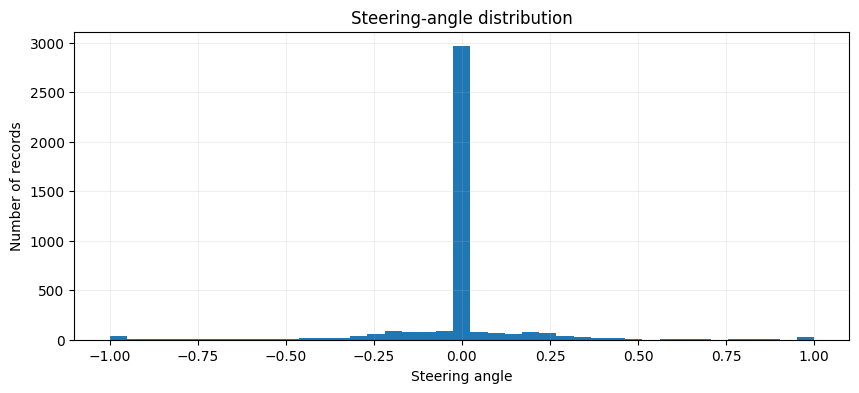

In [10]:
plt.figure(figsize=(10, 4))
plt.hist(data["steering"], bins=41)
plt.title("Steering-angle distribution")
plt.xlabel("Steering angle")
plt.ylabel("Number of records")
plt.grid(alpha=0.2)
plt.show()


In [11]:
train_rows, valid_rows = train_test_split(
    data, test_size=VALIDATION_SPLIT, random_state=SEED, shuffle=True
)
train_rows = train_rows.reset_index(drop=True)
valid_rows = valid_rows.reset_index(drop=True)

def expand_camera_samples(rows, include_side_cameras=True):
    paths, angles = [], []
    for row in rows.itertuples(index=False):
        angle = float(row.steering)
        paths.append(Path(row.center))
        angles.append(angle)
        if include_side_cameras:
            paths.extend([Path(row.left), Path(row.right)])
            angles.extend([angle + LEFT_RIGHT_CORRECTION, angle - LEFT_RIGHT_CORRECTION])
    return np.asarray(paths, dtype=object), np.asarray(angles, dtype=np.float32)

train_paths, train_angles = expand_camera_samples(train_rows, include_side_cameras=True)
valid_paths, valid_angles = expand_camera_samples(valid_rows, include_side_cameras=False)

print(f"Training samples (center + side cameras): {len(train_paths)}")
print(f"Validation samples (center camera only): {len(valid_paths)}")


Training samples (center + side cameras): 9726
Validation samples (center camera only): 811


Original shape: (160, 320, 3) | Model input shape: (66, 200, 3) | dtype: float32


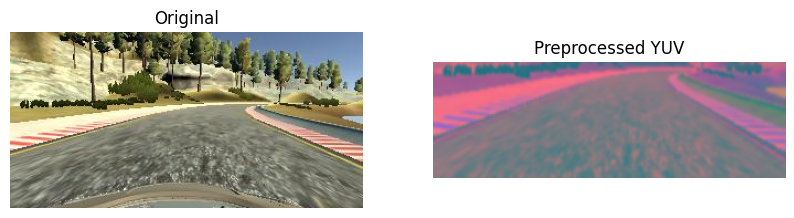

In [12]:
def read_rgb(path):
    with Image.open(path) as image:
        return np.asarray(image.convert("RGB"))

def preprocess_image(image):
    image = image[60:135, :, :]
    image = cv2.cvtColor(image, cv2.COLOR_RGB2YUV)
    image = cv2.GaussianBlur(image, (3, 3), 0)
    image = cv2.resize(image, (200, 66), interpolation=cv2.INTER_AREA)
    return image.astype(np.float32) / 255.0

def augment_image(image, steering):
    h, w = image.shape[:2]
    tx = random.uniform(-0.08, 0.08) * w
    ty = random.uniform(-0.04, 0.04) * h
    matrix = np.float32([[1, 0, tx], [0, 1, ty]])
    image = cv2.warpAffine(image, matrix, (w, h), borderMode=cv2.BORDER_REPLICATE)
    steering = steering + (tx / max(w, 1)) * 0.4

    if random.random() < 0.5:
        factor = random.uniform(0.7, 1.3)
        image = np.clip(image.astype(np.float32) * factor, 0, 255).astype(np.uint8)

    if random.random() < 0.5:
        image = cv2.flip(image, 1)
        steering = -steering

    return image, float(steering)

sample = read_rgb(train_paths[0])
processed = preprocess_image(sample)
print("Original shape:", sample.shape, "| Model input shape:", processed.shape, "| dtype:", processed.dtype)
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1); plt.imshow(sample); plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(processed); plt.title("Preprocessed YUV"); plt.axis("off")
plt.show()


In [13]:
class DrivingSequence(tf.keras.utils.Sequence):
    def __init__(self, paths, angles, batch_size=64, training=False, **kwargs):
        super().__init__(**kwargs)
        self.paths = np.asarray(paths, dtype=object)
        self.angles = np.asarray(angles, dtype=np.float32)
        self.batch_size = int(batch_size)
        self.training = bool(training)
        self.indices = np.arange(len(self.paths))
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.paths) / self.batch_size)

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size:(index + 1) * self.batch_size]
        images, angles = [], []
        for i in batch_indices:
            image = read_rgb(self.paths[i])
            angle = float(self.angles[i])
            if self.training:
                image, angle = augment_image(image, angle)
            images.append(preprocess_image(image))
            angles.append(angle)
        return np.asarray(images, dtype=np.float32), np.asarray(angles, dtype=np.float32)

    def on_epoch_end(self):
        if self.training:
            np.random.shuffle(self.indices)

train_gen = DrivingSequence(train_paths, train_angles, BATCH_SIZE, training=True)
valid_gen = DrivingSequence(valid_paths, valid_angles, BATCH_SIZE, training=False)

x_batch, y_batch = train_gen[0]
print("Batch image shape:", x_batch.shape)
print("Batch steering shape:", y_batch.shape)


Batch image shape: (64, 66, 200, 3)
Batch steering shape: (64,)


In [14]:
def build_model():
    model = Sequential([
        Input(shape=(66, 200, 3)),
        Conv2D(24, (5, 5), strides=(2, 2), activation="elu"),
        Conv2D(36, (5, 5), strides=(2, 2), activation="elu"),
        Conv2D(48, (5, 5), strides=(2, 2), activation="elu"),
        Conv2D(64, (3, 3), activation="elu"),
        Conv2D(64, (3, 3), activation="elu"),
        Flatten(),
        Dense(100, activation="elu"),
        Dense(50, activation="elu"),
        Dense(10, activation="elu"),
        Dense(1)
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="mse",
        metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return model

model = build_model()
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 31, 98, 24)        1824      
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 47, 36)        21636     
                                                                 
 conv2d_2 (Conv2D)           (None, 5, 22, 48)         43248     
                                                                 
 conv2d_3 (Conv2D)           (None, 3, 20, 64)         27712     
                                                                 
 conv2d_4 (Conv2D)           (None, 1, 18, 64)         36928     
                                                                 
 flatten (Flatten)           (None, 1152)              0         
                                                                 
 dense (Dense)               (None, 100)               1

In [18]:
best_model_path = OUTPUT_DIR / "best_model.keras"
callbacks = [
    ModelCheckpoint(str(best_model_path), monitor="val_loss", save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
]

history = model.fit(
    train_gen,
    steps_per_epoch=300,
    validation_data=valid_gen,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/10
152/300 [==============>...............] - ETA: 31s - loss: 0.0347 - mae: 0.1259WARNING:tensorflow:Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches (in this case, 3000 batches). You may need to use the repeat() function when building your dataset.

Epoch 1: val_loss improved from inf to 0.02424, saving model to c:\Users\sarva\Desktop\All projects\Self_Driving_Car\outputs\best_model.keras
300/300 [==============================] - 37s 122ms/step - loss: 0.0347 - mae: 0.1259 - val_loss: 0.0242 - val_mae: 0.0986


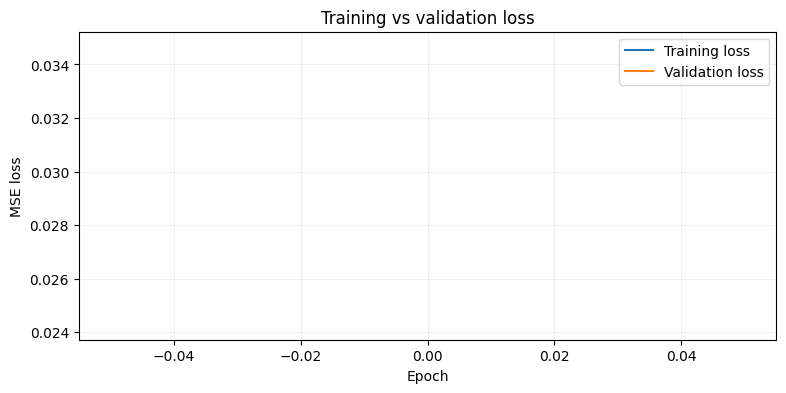

In [19]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training vs validation loss")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [20]:

final_model_path = OUTPUT_DIR / "steering_model.keras"
model.save(final_model_path)
print("Saved model:", final_model_path.resolve())

legacy_model_path = OUTPUT_DIR / "model.h5"
model.save(legacy_model_path)
print("Saved compatibility copy:", legacy_model_path.resolve())


Saved model: C:\Users\sarva\Desktop\All projects\Self_Driving_Car\outputs\steering_model.keras
Saved compatibility copy: C:\Users\sarva\Desktop\All projects\Self_Driving_Car\outputs\model.h5
